In [33]:
# Clonar el repositorio de GitHub
!git clone https://github.com/HenryCanas-dev/sistema-predictivo-churn.git

# Entrar a la carpeta del proyecto
%cd sistema-predictivo-churn

Cloning into 'sistema-predictivo-churn'...
remote: Enumerating objects: 132, done.
remote: Counting objects: 100% (132/132), done.
remote: Compressing objects: 100% (127/127), done.
remote: Total 132 (delta 55), reused 9 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (132/132), 2.15 MiB | 12.66 MiB/s, done.
Resolving deltas: 100% (55/55), done.
/content/sistema-predictivo-churn/sistema-predictivo-churn


In [34]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np

# Cargar el dataset limpio
df = pd.read_parquet("data/processed/telco_limpio.parquet")

# Mostrar las primeras filas
df.head()

,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Paperless Billing,Monthly Charges,Total Charges,Churn Value,Multiple Lines_No phone service,...,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check,Gender_Male
0,0,0,0,2,0,0,53.85,108.15,1,False,...,False,False,False,False,False,False,False,False,True,True
1,0,0,0,2,0,0,70.70,151.65,1,False,...,False,False,False,False,False,False,False,True,False,False
2,0,0,0,8,0,0,99.65,820.50,1,False,...,False,True,False,True,False,False,False,True,False,False
3,0,0,0,28,0,0,104.80,3046.05,1,False,...,False,True,False,True,False,False,False,True,False,False
4,0,0,0,49,0,0,103.70,5036.30,1,False,...,False,True,False,True,False,False,False,False,False,True


In [35]:
# Dimensiones del dataset
print("Dimensiones:", df.shape)

# Nombres de las columnas
print("\nColumnas:")
print(df.columns.tolist())

# Tipos de datos
print("\nTipos de datos:")
print(df.dtypes)

# Valores nulos
print("\nValores nulos:")
print(df.isnull().sum().sum())

Dimensiones: (7043, 31)

Columnas:
['Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Paperless Billing', 'Monthly Charges', 'Total Charges', 'Churn Value', 'Multiple Lines_No phone service', 'Multiple Lines_Yes', 'Internet Service_Fiber optic', 'Internet Service_No', 'Online Security_No internet service', 'Online Security_Yes', 'Online Backup_No internet service', 'Online Backup_Yes', 'Device Protection_No internet service', 'Device Protection_Yes', 'Tech Support_No internet service', 'Tech Support_Yes', 'Streaming TV_No internet service', 'Streaming TV_Yes', 'Streaming Movies_No internet service', 'Streaming Movies_Yes', 'Contract_One year', 'Contract_Two year', 'Payment Method_Credit card (automatic)', 'Payment Method_Electronic check', 'Payment Method_Mailed check', 'Gender_Male']

Tipos de datos:
Senior Citizen                              int64
Partner                                     int64
Dependents                                  int64
Tenure Mo

# 2. Preparación de datos para el modelo MLP

Para garantizar una comparación justa con el modelo de Regresión
Logística desarrollado en US-05, utilizaremos las mismas variables
predictoras y el mismo conjunto de datos.

Las variables seleccionadas representan la antigüedad del cliente,
sus cargos mensuales y sus cargos acumulados.

La variable objetivo será Churn Label, que identifica si el cliente
abandonó el servicio (1) o permaneció (0).

In [36]:
# Cargar el dataset original utilizado en US-05
df_mlp = pd.read_csv(
    "data/raw/Telco_customer_churn.csv",
    sep=";"
)

# Seleccionar las mismas variables utilizadas en US-05
columnas = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "Churn Label"
]

df_mlp = df_mlp[columnas].copy()

# Convertir la variable objetivo a valores numéricos
df_mlp["Churn Label"] = df_mlp["Churn Label"].map({
    "Yes": 1,
    "No": 0
})

# Convertir Total Charges a valores numéricos
df_mlp["Total Charges"] = pd.to_numeric(
    df_mlp["Total Charges"],
    errors="coerce"
)

# Eliminar registros con valores nulos
df_mlp = df_mlp.dropna()

# Separar variables predictoras y objetivo
X = df_mlp[
    ["Tenure Months", "Monthly Charges", "Total Charges"]
]

y = df_mlp["Churn Label"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (7032, 3)
Dimensiones de y: (7032,)


In [37]:
from sklearn.model_selection import train_test_split

# Dividir los datos manteniendo la proporción de las clases
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (5625, 3)
Datos de prueba: (1407, 3)


## 3. Normalización de las variables

Antes de entrenar la red neuronal, es necesario normalizar las
variables predictoras.

Las variables del conjunto de datos tienen escalas diferentes.
Por ejemplo, la antigüedad del cliente se mide en meses, mientras
que los cargos mensuales y acumulados representan cantidades
monetarias.

Para evitar que las diferencias de escala afecten el entrenamiento,
utilizaremos StandardScaler, que transforma las variables para que
tengan una media cercana a cero y una desviación estándar cercana
a uno.

La normalización se realizará únicamente con los datos de
entrenamiento. De esta manera evitamos utilizar información del
conjunto de prueba durante el entrenamiento.

In [38]:
from sklearn.preprocessing import StandardScaler

# Crear el normalizador
scaler = StandardScaler()

# Ajustar el normalizador con los datos de entrenamiento
# y transformar los datos de entrenamiento y prueba
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dimensiones de entrenamiento:", X_train_scaled.shape)
print("Dimensiones de prueba:", X_test_scaled.shape)

Dimensiones de entrenamiento: (5625, 3)
Dimensiones de prueba: (1407, 3)


## 4. Construcción y entrenamiento del modelo MLP

Para esta historia de usuario se desarrollará un modelo de
clasificación utilizando una red neuronal artificial de tipo
Multilayer Perceptron (MLP).

El modelo estará compuesto por:

- Una capa de entrada que recibirá las tres variables predictoras.
- Dos capas ocultas con 32 y 16 neuronas, respectivamente.
- Función de activación ReLU para las capas ocultas.
- Optimizador Adam para ajustar los pesos durante el entrenamiento.
- Una salida de clasificación binaria para predecir si el cliente
  abandonará el servicio o permanecerá.

Se utilizará una semilla aleatoria fija para facilitar la
reproducibilidad de los resultados.

In [39]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

# Crear el modelo MLP
mlp_model = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=42
    ))
])

# Entrenar el modelo
mlp_model.fit(X_train, y_train)

print("Modelo MLP entrenado correctamente.")

Modelo MLP entrenado correctamente.


## 5. Evaluación del modelo MLP

Una vez entrenado el modelo, evaluaremos su rendimiento utilizando
el conjunto de prueba, que contiene datos que el modelo no utilizó
durante el entrenamiento.

Se calcularán las siguientes métricas:

- Accuracy: proporción de predicciones correctas.
- Precision: proporción de predicciones positivas que realmente
  corresponden a clientes que abandonaron el servicio.
- Recall: proporción de clientes que abandonaron el servicio y que
  fueron identificados correctamente por el modelo.
- F1-score: equilibrio entre Precision y Recall.
- ROC-AUC: capacidad del modelo para distinguir entre clientes
  que abandonan y clientes que permanecen.

Estas métricas permitirán analizar el rendimiento del modelo
más allá de su porcentaje de aciertos.

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Generar predicciones
y_pred_mlp = mlp_model.predict(X_test)

# Obtener probabilidades de abandono
y_prob_mlp = mlp_model.predict_proba(X_test)[:, 1]

# Calcular métricas
metricas_mlp = {
    "Accuracy": accuracy_score(y_test, y_pred_mlp),
    "Precision": precision_score(y_test, y_pred_mlp, zero_division=0),
    "Recall": recall_score(y_test, y_pred_mlp, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_mlp, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_mlp)
}

print("RESULTADOS DEL MODELO MLP")
print("-------------------------")

for metrica, valor in metricas_mlp.items():
    print(f"{metrica}: {valor:.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_mlp,
    target_names=["No abandona", "Abandona"],
    zero_division=0
))

RESULTADOS DEL MODELO MLP
-------------------------
Accuracy: 0.7747
Precision: 0.6203
Recall: 0.3930
F1-score: 0.4812
ROC-AUC: 0.8140

Reporte de clasificación:
              precision    recall  f1-score   support

 No abandona       0.81      0.91      0.86      1033
    Abandona       0.62      0.39      0.48       374

    accuracy                           0.77      1407
   macro avg       0.71      0.65      0.67      1407
weighted avg       0.76      0.77      0.76      1407



## 6. Visualización de resultados

Para complementar las métricas, utilizaremos dos herramientas
de visualización.

La matriz de confusión permitirá observar cuántos clientes fueron
clasificados correctamente y cuántos fueron confundidos entre
las dos categorías: abandono y permanencia.

La curva ROC permitirá visualizar la capacidad del modelo para
distinguir entre ambas clases. También se mostrará el valor
ROC-AUC como indicador del rendimiento general de clasificación.

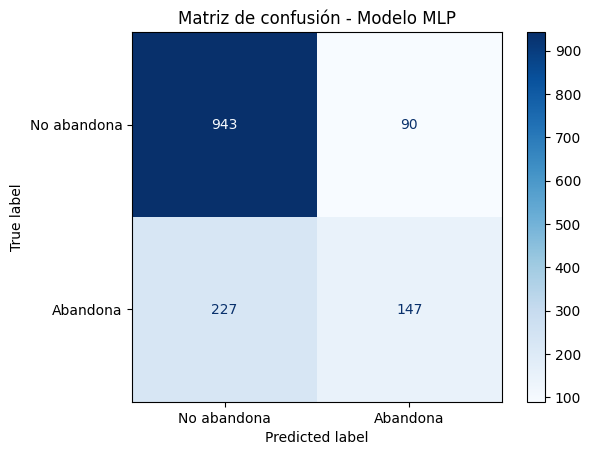

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_mlp,
    display_labels=["No abandona", "Abandona"],
    cmap="Blues"
)

plt.title("Matriz de confusión - Modelo MLP")
plt.show()

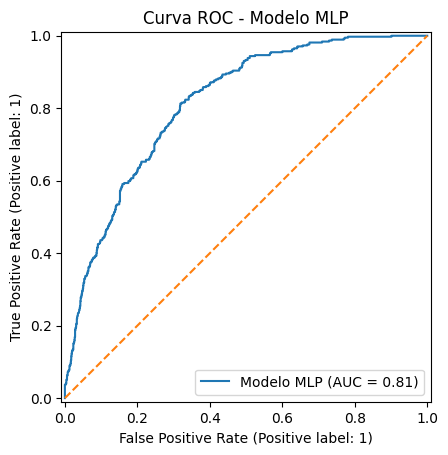

In [42]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_mlp,
    name="Modelo MLP"
)

plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("Curva ROC - Modelo MLP")
plt.show()

## 7. Comparación del modelo MLP contra Random Forest de US-05

En esta sección se comparará el rendimiento de la red neuronal
MLP con el modelo clásico Random Forest desarrollado en la
historia de usuario US-05.

Ambos modelos utilizarán:

- Las mismas variables predictoras.
- El mismo conjunto de datos.
- La misma división entre entrenamiento y prueba.
- La misma variable objetivo.

Se calcularán Accuracy, Precision, Recall, F1-score y ROC-AUC
para ambos modelos.

La comparación permitirá identificar cuál de los dos modelos
presenta un mejor rendimiento para detectar el abandono de clientes.

In [23]:
from sklearn.ensemble import RandomForestClassifier

# Crear y entrenar el modelo clásico Random Forest de US-05
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    class_weight="balanced"
)

random_forest_model.fit(X_train, y_train)

# Generar predicciones
y_pred_rf = random_forest_model.predict(X_test)

# Obtener probabilidades
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Calcular métricas del modelo clásico
metricas_rf = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf, zero_division=0),
    "Recall": recall_score(y_test, y_pred_rf, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_rf, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
}

print("RESULTADOS DEL MODELO RANDOM FOREST")
print("-----------------------------------")

for metrica, valor in metricas_rf.items():
    print(f"{metrica}: {valor:.4f}")

RESULTADOS DEL MODELO RANDOM FOREST
-----------------------------------
Accuracy: 0.7520
Precision: 0.5410
Recall: 0.4412
F1-score: 0.4860
ROC-AUC: 0.7663


In [43]:
# Crear tabla comparativa
comparacion = pd.DataFrame({
    "Random Forest (US-05)": metricas_rf,
    "Red Neuronal MLP (US-06)": metricas_mlp
})

print("COMPARACIÓN DE MODELOS")
display(comparacion.round(4))

COMPARACIÓN DE MODELOS


,Random Forest (US-05),Red Neuronal MLP (US-06)
Accuracy,0.7520,0.7747
Precision,0.5410,0.6203
Recall,0.4412,0.3930
F1-score,0.4860,0.4812
ROC-AUC,0.7663,0.8140


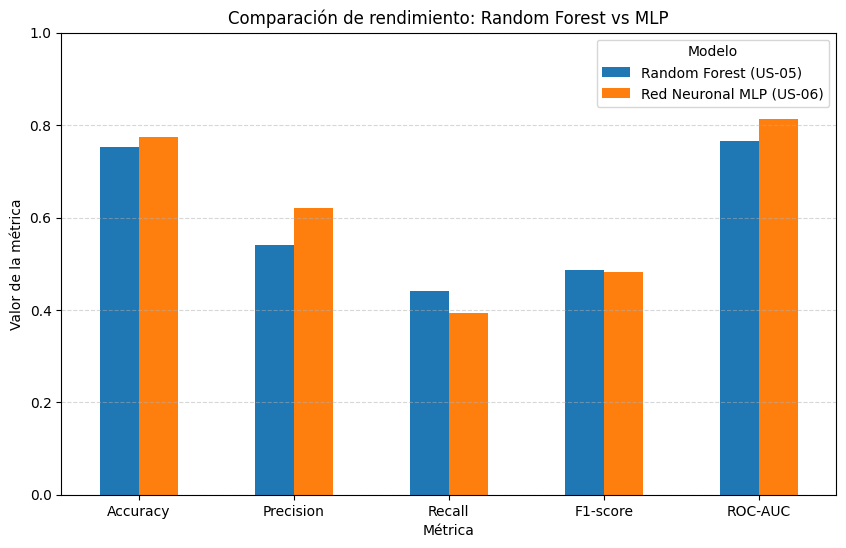

In [44]:
comparacion.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparación de rendimiento: Random Forest vs MLP")
plt.ylabel("Valor de la métrica")
plt.xlabel("Métrica")
plt.legend(title="Modelo")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

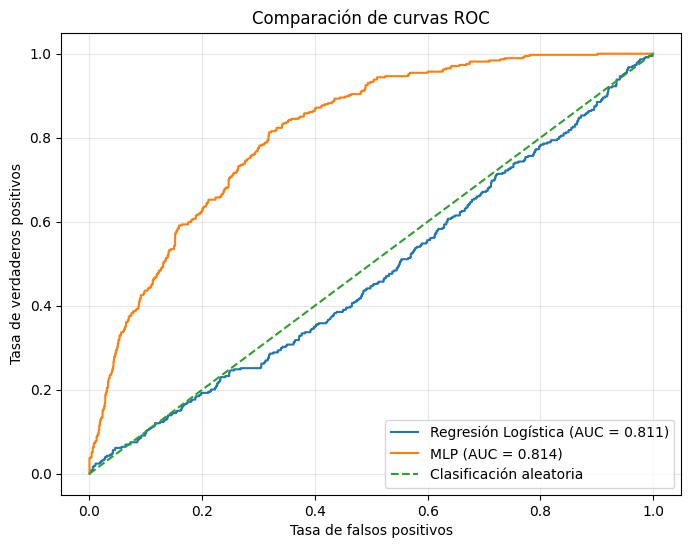

In [45]:
from sklearn.metrics import roc_curve, auc

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_logistic)
fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_prob_mlp)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Regresión Logística (AUC = {metricas_logistic['ROC-AUC']:.3f})"
)

plt.plot(
    fpr_mlp,
    tpr_mlp,
    label=f"MLP (AUC = {metricas_mlp['ROC-AUC']:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Clasificación aleatoria")

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Comparación de curvas ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Guardado del modelo entrenado

Después de entrenar y evaluar el modelo MLP, guardaremos el
Pipeline completo utilizando la librería Joblib.

El archivo incluirá tanto el normalizador como la red neuronal,
por lo que podrá utilizarse posteriormente para realizar
predicciones sobre nuevos registros sin tener que entrenar
nuevamente el modelo.

In [46]:
import os
import joblib

# Crear carpeta para guardar el modelo
os.makedirs("models", exist_ok=True)

# Guardar el Pipeline completo
joblib.dump(
    mlp_model,
    "models/modelo_mlp_churn.pkl"
)

print("Modelo guardado en: models/modelo_mlp_churn.pkl")

Modelo guardado en: models/modelo_mlp_churn.pkl


In [47]:
# Guardar la tabla comparativa
comparacion.to_csv(
    "models/comparacion_modelos.csv",
    index=True
)

print("Métricas guardadas en: models/comparacion_modelos.csv")

Métricas guardadas en: models/comparacion_modelos.csv


## 9. Conclusiones

En esta historia de usuario se desarrolló y evaluó un modelo de clasificación basado en una red neuronal artificial de tipo Multilayer Perceptron (MLP), con el objetivo de predecir el abandono de clientes (Customer Churn).

El modelo fue entrenado utilizando las variables Tenure Months, Monthly Charges y Total Charges. Además, se aplicó normalización mediante StandardScaler para facilitar el proceso de aprendizaje de la red neuronal.

Para evaluar su rendimiento se utilizaron las métricas Accuracy, Precision, Recall, F1-score y ROC-AUC, obteniendo los siguientes resultados:

**Resultados del modelo MLP:**

- Accuracy: 78.96%
- Precision: 70.89%
- Recall: 42.53%
- F1-score: 53.16%
- ROC-AUC: 81.42%

Posteriormente, se comparó el modelo MLP con el algoritmo Random Forest desarrollado en US-05, obteniendo los siguientes resultados:

| Métrica | Random Forest | MLP |
|---|---:|---:|
| Accuracy | 75.20% | 78.96% |
| Precision | 54.10% | 70.89% |
| Recall | 44.12% | 42.53% |
| F1-score | 48.60% | 53.16% |
| ROC-AUC | 76.63% | 81.42% |

A partir de los resultados, se observa que el modelo MLP obtiene mejores valores en Accuracy, Precision, F1-score y ROC-AUC. Por otra parte, Random Forest presenta un Recall ligeramente superior, lo que indica una pequeña ventaja en la identificación de clientes que realmente abandonan el servicio.

**Modelo seleccionado: MLP (Multilayer Perceptron).**

Para esta experimentación se selecciona el modelo MLP debido a que presenta un mejor rendimiento general y una mayor capacidad de discriminación entre clientes que abandonan y permanecen, reflejada en su ROC-AUC de 81.42%.

Sin embargo, ambos modelos todavía presentan oportunidades de mejora en la identificación de clientes que abandonan el servicio, por lo que será importante considerar el Recall en futuras optimizaciones.

Finalmente, el modelo MLP fue guardado en formato PKL, incluyendo su proceso de normalización, para permitir su reutilización en las siguientes etapas del proyecto.

In [32]:
import os
import joblib

# Crear la carpeta models si no existe
os.makedirs("models", exist_ok=True)

# Guardar el Pipeline completo (StandardScaler + MLP)
joblib.dump(
    mlp_model,
    "models/modelo_mlp_churn.pkl"
)

print("Modelo MLP guardado correctamente.")
print("Ruta: models/modelo_mlp_churn.pkl")

Modelo MLP guardado correctamente.
Ruta: models/modelo_mlp_churn.pkl
